BlinkIT Grocery Sales Analysis
------------------------------

Domain: Retail & Grocery Sales Analytics 
------------------------------------------------------------------------
Company: Sapphire IQ 
------------------------------------------------------------------------
Tools Used: Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook
-------------------------------------------------------------------------

Objectives and Tasks 
--------------------


Objective 1: Understand the Business and Its Sales Performance 
------------------------------------------------------------------------

IMPORT LIBRARIES
-----------------

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings("ignore")

In [2]:
df =pd.read_excel("BlinkIT Grocery Data.xlsx")
df

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,low fat,NCT53,Health and Hygiene,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0


In [3]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [4]:
df.tail()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8518,low fat,NCT53,Health and Hygiene,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


In [5]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

In [6]:
df.shape

(8523, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [8]:
df.describe

<bound method NDFrame.describe of      Item Fat Content Item Identifier              Item Type  \
0             Regular           FDX32  Fruits and Vegetables   
1             Low Fat           NCB42     Health and Hygiene   
2             Regular           FDR28           Frozen Foods   
3             Regular           FDL50                 Canned   
4             Low Fat           DRI25            Soft Drinks   
...               ...             ...                    ...   
8518          low fat           NCT53     Health and Hygiene   
8519          low fat           FDN09            Snack Foods   
8520          low fat           DRE13            Soft Drinks   
8521              reg           FDT50                  Dairy   
8522              reg           FDM58            Snack Foods   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
0                          2012            OUT049               Tier 1   
1                          2022            OUT018

Understand what types of products does  BlinkIT is selling
----------------------------------------------------------

In [9]:
df["Item Type"].unique()

array(['Fruits and Vegetables', 'Health and Hygiene', 'Frozen Foods',
       'Canned', 'Soft Drinks', 'Household', 'Snack Foods', 'Meat',
       'Breads', 'Hard Drinks', 'Others', 'Dairy', 'Breakfast',
       'Baking Goods', 'Seafood', 'Starchy Foods'], dtype=object)

In [10]:
df["Item Type"].nunique()

16

In [11]:
df["Item Type"].value_counts()

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

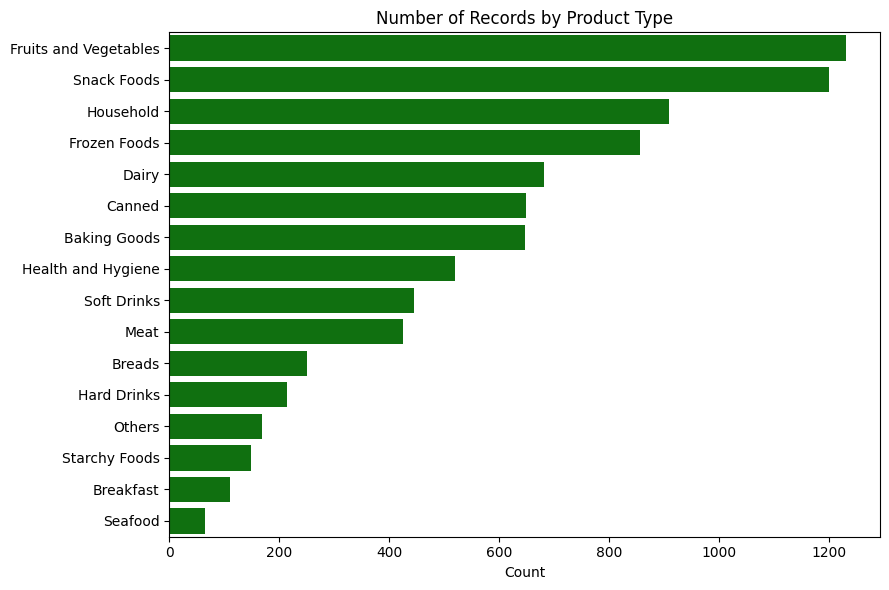

In [12]:
plt.figure(figsize=(9,6))
sns.barplot(x=df["Item Type"].value_counts(),y=df["Item Type"].value_counts().index,color="green")
plt.title("Number of Records by Product Type")
plt.xlabel("Count")
plt.ylabel("")
plt.tight_layout()
plt.show()

Understand the different types and locations of BlinkIT outlets
---------------------------------------------------------------

In [13]:
df["Outlet Type"].value_counts()

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

In [14]:
df["Outlet Location Type"].value_counts()

Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

In [15]:
df["Outlet Size"].value_counts()

Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

In [16]:
print("Outlets:",df["Outlet Identifier"].nunique())
print(df.groupby("Outlet Identifier")[["Outlet Type","Outlet Size","Outlet Location Type"]].nunique())
print("\n(A number above 1 means the outlet has more than one value - checked and fixed )")
      

Outlets: 10
                   Outlet Type  Outlet Size  Outlet Location Type
Outlet Identifier                                                
OUT010                       1            3                     1
OUT013                       1            1                     1
OUT017                       1            3                     1
OUT018                       1            1                     1
OUT019                       1            1                     1
OUT027                       1            1                     1
OUT035                       1            1                     1
OUT045                       1            3                     1
OUT046                       1            1                     1
OUT049                       1            1                     1

(A number above 1 means the outlet has more than one value - checked and fixed )


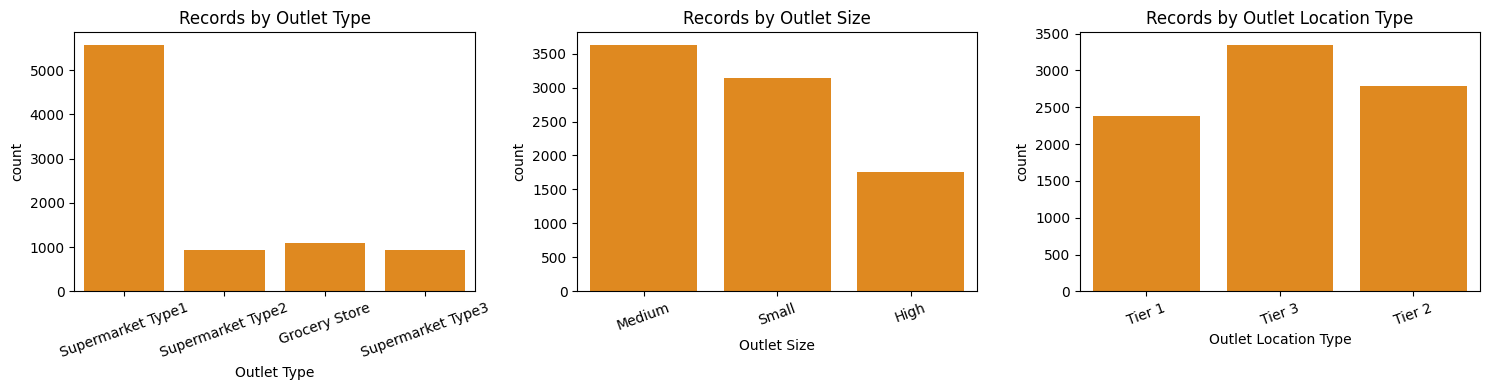

In [17]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
for i,col in enumerate(["Outlet Type","Outlet Size","Outlet Location Type"]):
    sns.countplot(data=df,x=col,ax=ax[i],color="darkorange")
    ax[i].set_title("Records by " + col)
    ax[i].tick_params(axis="x",rotation=20)
plt.tight_layout()
plt.show()

Understand how much BlinkIT is selling overall
----------------------------------------------

In [18]:
print("Total Sales",df["Sales"].sum())
print("Avg Sales",df["Sales"].mean())
print("Max Sales",df["Sales"].max())
print("Min Sales",df["Sales"].min())
print("Average Rating",df["Rating"].mean())

Total Sales 1201681.4928
Avg Sales 140.99278338613163
Max Sales 266.8884
Min Sales 31.29
Average Rating 3.965857092573038


Text(0, 0.5, 'Number of records')

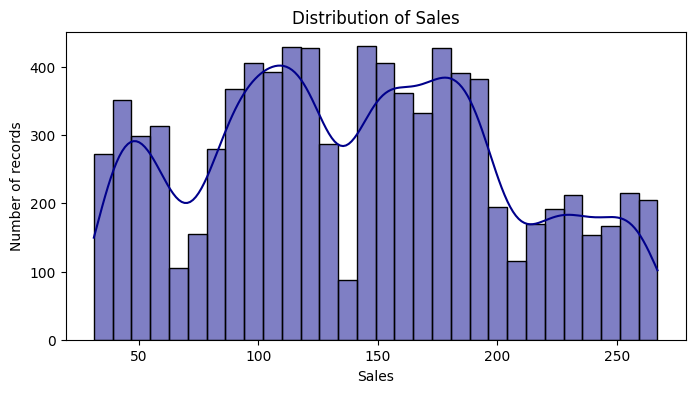

In [19]:
plt.figure(figsize=(8,4))
sns.histplot(data=df,x="Sales",kde=True,bins=30,color="darkblue")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of records")

Overall customer rating and product performance
-----------------------------------------------

In [20]:
rating_by_item = df.groupby('Item Type')['Rating'].mean().sort_values(ascending=False)
rating_by_item

Item Type
Meat                     4.023059
Household                3.998681
Canned                   3.994299
Health and Hygiene       3.986154
Baking Goods             3.983025
Frozen Foods             3.971145
Dairy                    3.965836
Seafood                  3.959375
Fruits and Vegetables    3.956169
Others                   3.954438
Snack Foods              3.948917
Breakfast                3.932727
Soft Drinks              3.920674
Starchy Foods            3.920270
Hard Drinks              3.907477
Breads                   3.881275
Name: Rating, dtype: float64

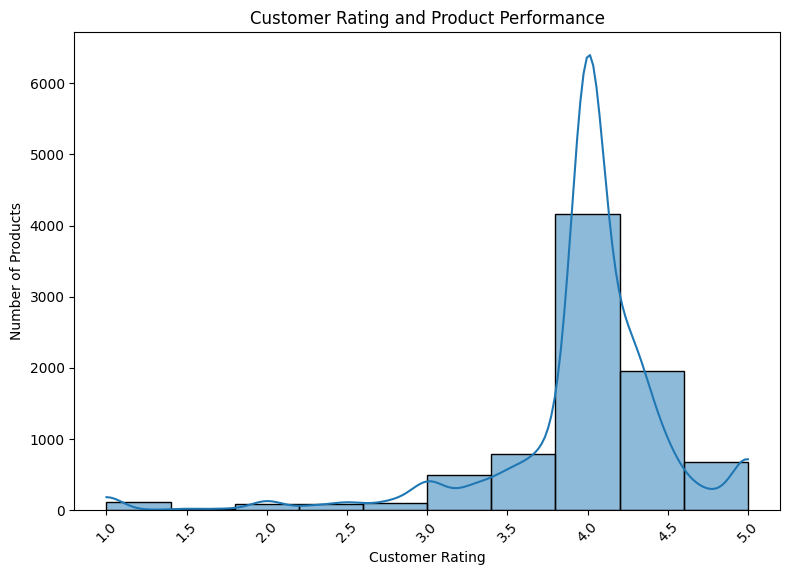

In [21]:
plt.figure(figsize=(8,6))
sns.histplot(df['Rating'],bins=10,kde=True)
plt.title("Customer Rating and Product Performance")
plt.xlabel('Customer Rating')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.suptitle('')
plt.tight_layout()
plt.show()

In [22]:
print("Average Rating:",round(df["Rating"].mean(),2))
print(df["Rating"].describe())

Average Rating: 3.97
count    8523.000000
mean        3.965857
std         0.605651
min         1.000000
25%         4.000000
50%         4.000000
75%         4.200000
max         5.000000
Name: Rating, dtype: float64


Objective 2: Make Sure the Available Information Is Reliable 
-----------------------------------------------------------------

 Find information that is missing from the available records. 
-------------------------------------------------------------

In [23]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [24]:
df.isnull().sum()/len(df)*100 #Missing va;ue in terms of percentage

Item Fat Content              0.000000
Item Identifier               0.000000
Item Type                     0.000000
Outlet Establishment Year     0.000000
Outlet Identifier             0.000000
Outlet Location Type          0.000000
Outlet Size                   0.000000
Outlet Type                   0.000000
Item Visibility               0.000000
Item Weight                  17.165317
Sales                         0.000000
Rating                        0.000000
dtype: float64

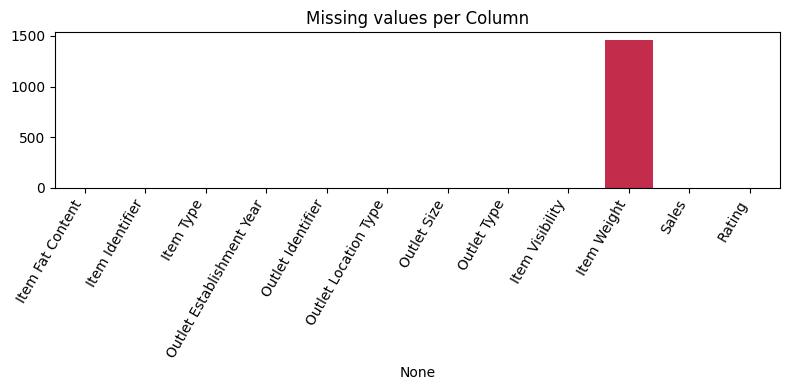

In [25]:
plt.figure(figsize=(8,4))
sns.barplot(x=df.isnull().sum().index,y=df.isnull().sum().values,color="crimson")
plt.xticks(rotation=60,ha="right")
plt.title("Missing values per Column")
plt.tight_layout()
plt.show()

In [26]:
df["Item Weight"]=df["Item Weight"].fillna(df.groupby("Item Identifier")["Item Weight"].transform("mean"))
df["Item Weight"]=df["Item Weight"].fillna(df["Item Weight"].median())

In [27]:
df["Item Visibility"]=df["Item Visibility"].replace(0,np.nan)
df["Item Visibility"]=df["Item Visibility"].fillna(df.groupby("Item Identifier")["Item Visibility"].transform("mean"))
df["Item Visibility"]=df["Item Visibility"].fillna(df["Item Visibility"].median())
print("\nMissing values after cleaning:",df.isnull().sum().sum())


Missing values after cleaning: 0


 Find information that has been repeated more than once.
--------------------------------------------------------   

In [28]:
print(df.duplicated().sum())

0


Find values that look unusually high or unusually low. 
-----------------------------------------------------

In [29]:
for col in ["Sales","Item Visibility","Item Weight","Rating"]:
    q1,q3=df[col].quantile(0.25),df[col].quantile(0.75)
    iqr=q3-q1
    low,high=q1-1.5*iqr,q3+1.5*iqr
    n=((df[col]<low) | (df[col]>high)).sum()
    print(f"{col:16s} outliers:{n:5d} (allowance range {low:3f} to {high:3f})")

Sales            outliers:    0 (allowance range -43.899300 to 323.369500)
Item Visibility  outliers:  144 (allowance range -0.069814 to 0.200075)
Item Weight      outliers:    0 (allowance range -3.312500 to 28.947500)
Rating           outliers: 1931 (allowance range 3.700000 to 4.500000)



Note: Rating outliers are real customer scores (most ratings are exactly 4.0), so we KEEP them. Visibility outliers are also kept - they are genuine, just very visible items.


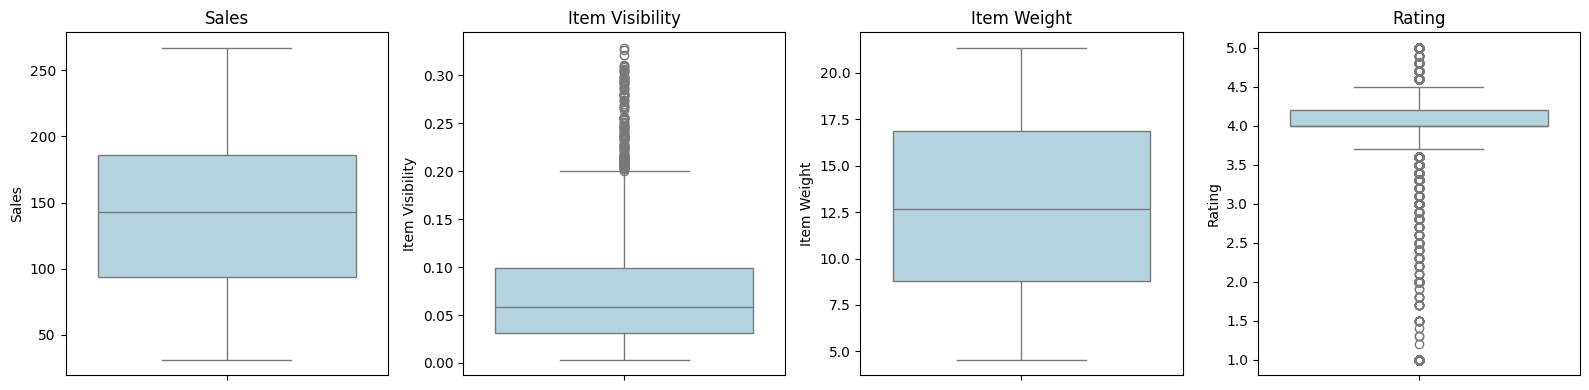

In [30]:
print("\nNote: Rating outliers are real customer scores (most ratings are exactly 4.0), so we KEEP them. Visibility outliers are also kept - they are genuine, just very visible items.")
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(["Sales", "Item Visibility", "Item Weight", "Rating"]):
    sns.boxplot(y=df[col], ax=ax[i], color="lightblue")
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

Make sure similar information is presented in the same way for proper comparison
--------------------------------------------------------------------------------

In [31]:
df['Item Fat Content'].unique()

array(['Regular', 'Low Fat', 'low fat', 'LF', 'reg'], dtype=object)

In [32]:
df['Item Fat Content']=df['Item Fat Content'].replace({'reg':'Regular','low fat':'Low Fat','LF':'Low Fat'})
df

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,Low Fat,NCT53,Health and Hygiene,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.066317,5.40,164.5526,4.0
8519,Low Fat,FDN09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,14.15,241.6828,4.0
8520,Low Fat,DRE13,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,6.28,86.6198,4.0
8521,Regular,FDT50,Dairy,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,6.75,97.8752,4.0


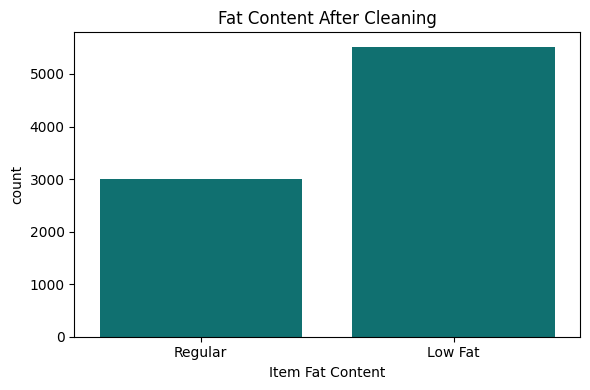

In [33]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x="Item Fat Content",color="teal")
plt.title("Fat Content After Cleaning")
plt.tight_layout()
plt.show()

Objective 3: Find Out What is Driving Better Sales Performance
-------------------------------------------------------------

Find out what types of products are selling more
------------------------------------------------

In [34]:
df.groupby("Item Type")["Sales"].sum()

Item Type
Baking Goods              81894.7364
Breads                    35379.1198
Breakfast                 15596.6966
Canned                    90706.7290
Dairy                    101276.4616
Frozen Foods             118558.8814
Fruits and Vegetables    178124.0810
Hard Drinks               29334.6806
Health and Hygiene        68025.8388
Household                135976.5254
Meat                      59449.8638
Others                    22451.8916
Seafood                    9077.8700
Snack Foods              175433.9224
Soft Drinks               58514.1670
Starchy Foods             21880.0274
Name: Sales, dtype: float64

In [35]:
item_sales=df.groupby("Item Type")["Sales"].agg(["sum","mean","count"]).sort_values("sum",ascending=False)
item_sales.columns=["Total Sales","Avg Sales","Records"]
print(item_sales.round(2))

                       Total Sales  Avg Sales  Records
Item Type                                             
Fruits and Vegetables    178124.08     144.58     1232
Snack Foods              175433.92     146.19     1200
Household                135976.53     149.42      910
Frozen Foods             118558.88     138.50      856
Dairy                    101276.46     148.50      682
Canned                    90706.73     139.76      649
Baking Goods              81894.74     126.38      648
Health and Hygiene        68025.84     130.82      520
Meat                      59449.86     139.88      425
Soft Drinks               58514.17     131.49      445
Breads                    35379.12     140.95      251
Hard Drinks               29334.68     137.08      214
Others                    22451.89     132.85      169
Starchy Foods             21880.03     147.84      148
Breakfast                 15596.70     141.79      110
Seafood                    9077.87     141.84       64


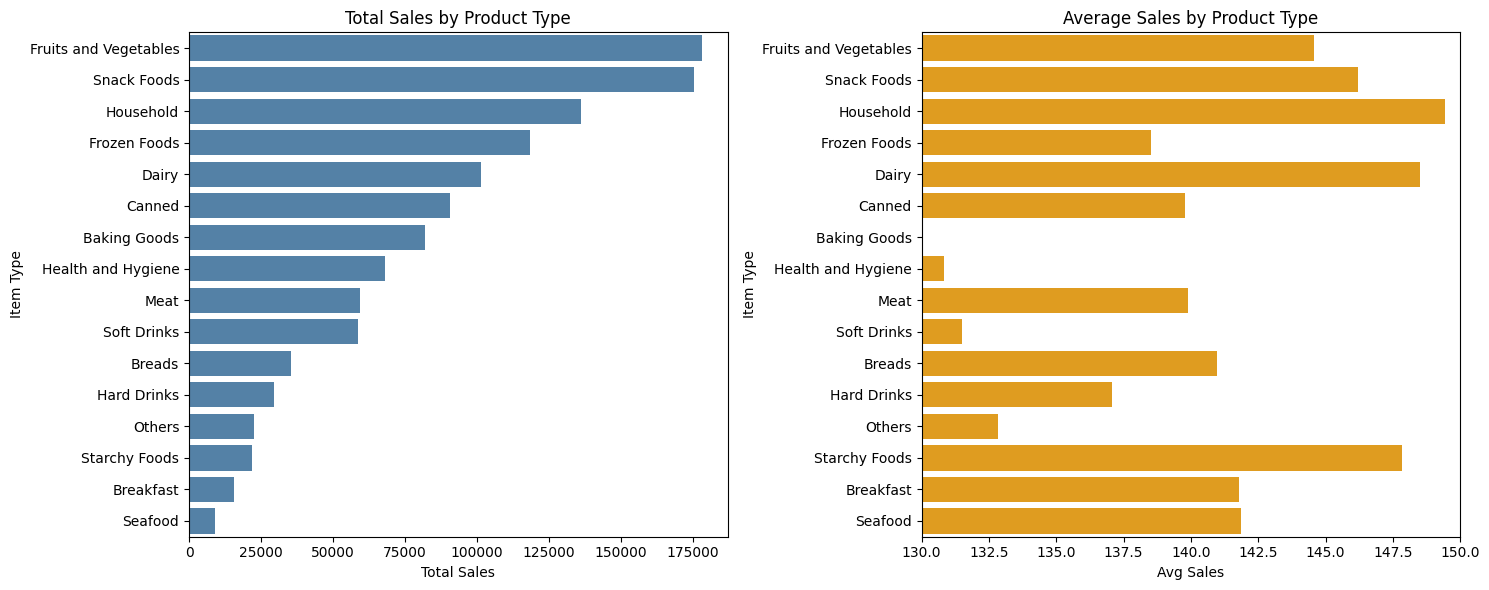

In [36]:
fig,ax=plt.subplots(1,2,figsize=(15,6))
sns.barplot(x=item_sales["Total Sales"],y=item_sales.index,color="steelblue",ax=ax[0])
ax[0].set_title("Total Sales by Product Type")
sns.barplot(x=item_sales["Avg Sales"],y=item_sales.index,color="orange",ax=ax[1])
ax[1].set_title("Average Sales by Product Type")
ax[1].set_xlim(130,150)
plt.tight_layout()
plt.show()

In [37]:
df.groupby("Item Fat Content")["Sales"].sum().round(0)

Item Fat Content
Low Fat    776320.0
Regular    425362.0
Name: Sales, dtype: float64

Find out which type of outlets performing better 
--------------------------------------------------

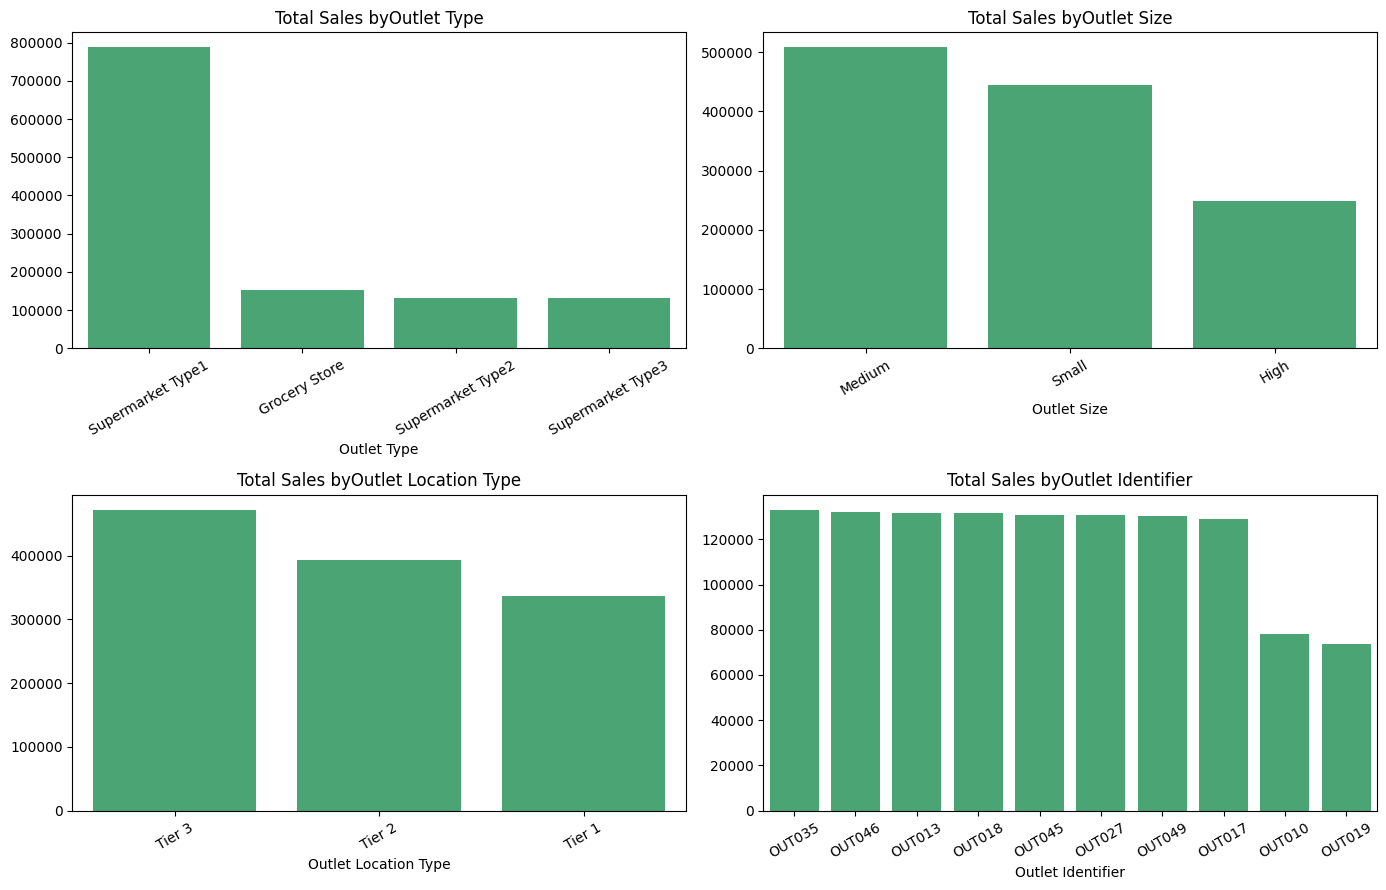

In [38]:
fig,ax=plt.subplots(2,2,figsize=(14,9))
for a,col in zip(ax.flatten(),["Outlet Type","Outlet Size","Outlet Location Type","Outlet Identifier"]):
    s=df.groupby(col)["Sales"].sum().sort_values(ascending=False)
    sns.barplot(x=s.index,y=s.values,ax=a,color="mediumseagreen")
    a.set_title("Total Sales by"+col)
    a.tick_params(axis="x",rotation=30)
plt.tight_layout()

In [39]:
print(df.groupby("Outlet Type")["Sales"].agg(["sum","mean","count"]).round(2))

                         sum    mean  count
Outlet Type                                
Grocery Store      151939.15  140.29   1083
Supermarket Type1  787549.89  141.21   5577
Supermarket Type2  131477.78  141.68    928
Supermarket Type3  130714.67  139.80    935


Understand whether product visibility weight,rating and outlet characteristics are connected with sales
------------------------------------------------------------------

In [40]:
num_cols = ["Sales","Item Visibility","Item Weight","Rating"]
corr=df[num_cols].corr()
print(corr["Sales"].round(3))

Sales              1.000
Item Visibility   -0.006
Item Weight        0.026
Rating             0.011
Name: Sales, dtype: float64


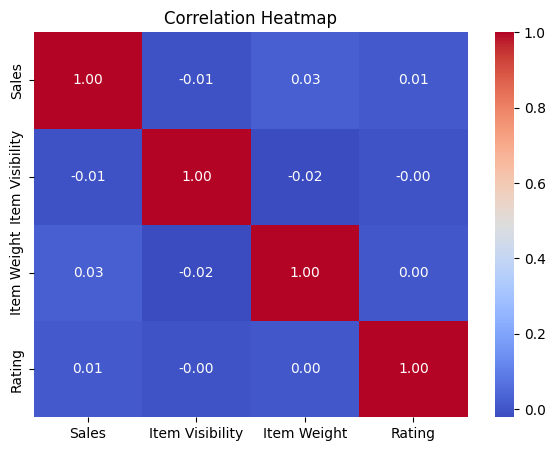

In [41]:
plt.figure(figsize=(7,5))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

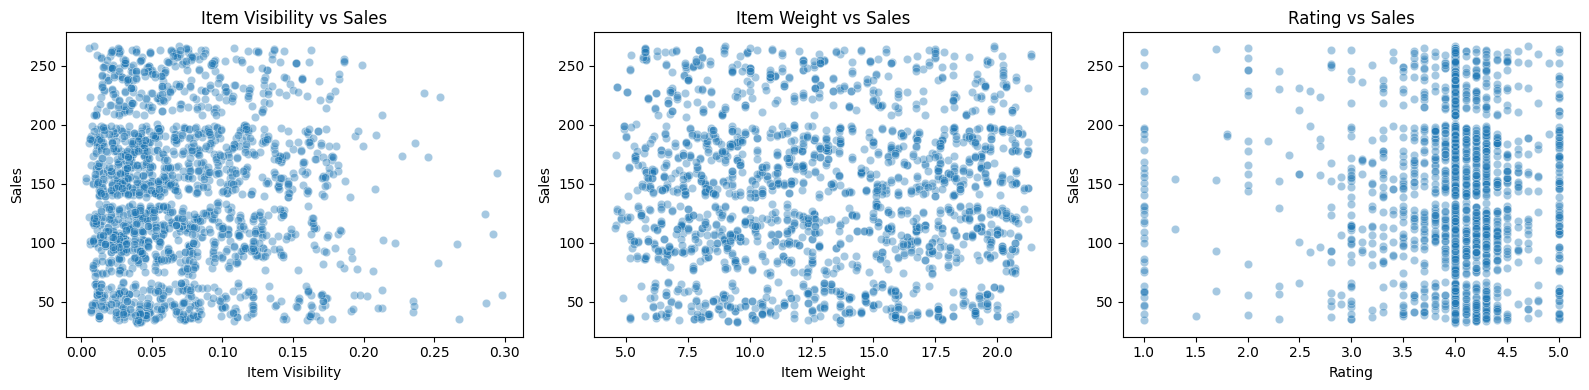

In [42]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,["Item Visibility","Item Weight","Rating"]):
    sns.scatterplot(data=df.sample(2000,random_state=1),x=col,y="Sales",alpha=0.4,ax=ax)
    ax.set_title(col + " vs Sales")
plt.tight_layout()
plt.show()

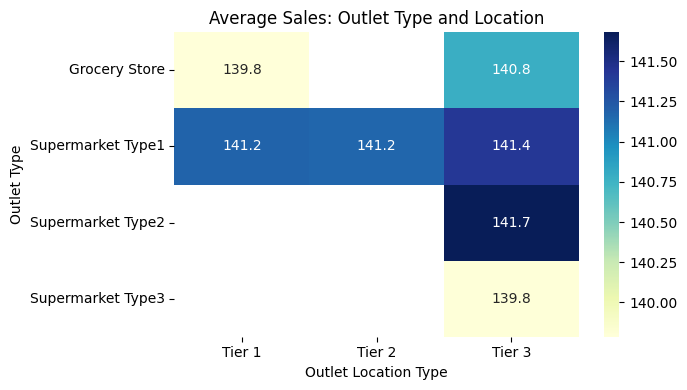

In [43]:
pivot = df.pivot_table(values ="Sales",index="Outlet Type",columns="Outlet Location Type",aggfunc="mean")
plt.figure(figsize=(7,4))
sns.heatmap(pivot,annot=True,fmt=".1f",cmap="YlGnBu")
plt.title("Average Sales: Outlet Type and Location")
plt.tight_layout()
plt.show()

Compare better and lower performing products and outlets to understand the difference
--------------------------------------------------------------------------------------

In [44]:
high=df[df["Sales"]>=df["Sales"].quantile(0.75)]
low=df[df["Sales"]<=df["Sales"].quantile(0.25)]


 Outlet Type share (%) - High vs Low
                   High   Low
Outlet Type                  
Grocery Store      12.3  12.9
Supermarket Type1  65.7  65.0
Supermarket Type2  11.4  10.7
Supermarket Type3  10.6  11.3


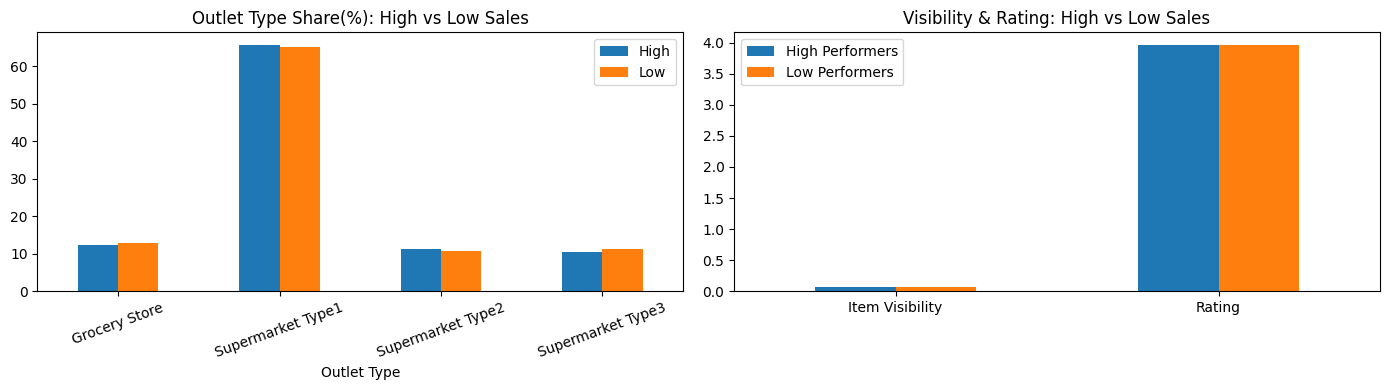

In [45]:
compare=pd.DataFrame({"High Performers":high[["Item Visibility","Item Weight","Rating"]].mean(),
                      "Low Performers":low[["Item Visibility","Item Weight","Rating"]].mean()})
print("\n Outlet Type share (%) - High vs Low")
print(pd.DataFrame({"High":high["Outlet Type"].value_counts(normalize=True)*100,
                    "Low":low["Outlet Type"].value_counts(normalize=True)*100}).round(1))
fig,ax=plt.subplots(1,2,figsize=(14,4))
pd.DataFrame({"High":high["Outlet Type"].value_counts(normalize=True)*100,
                    "Low":low["Outlet Type"].value_counts(normalize=True)*100}).plot(kind="bar",ax=ax[0])
ax[0].set_title("Outlet Type Share(%): High vs Low Sales")
ax[0].tick_params(axis="x",rotation=20)
compare.loc[["Item Visibility","Rating"]].plot(kind="bar",ax=ax[1])
ax[1].set_title("Visibility & Rating: High vs Low Sales")
ax[1].tick_params(axis="x",rotation=0)
plt.tight_layout()
plt.show()

 Objective 4: Help Management Make Better Business Decisions
-------------------------------------------------------------

Identify the products that are contributing more to sales
----------------------------------------------------------

In [46]:
top_types=df.groupby("Item Type")["Sales"].sum().sort_values(ascending=False)
share=(top_types/top_types.sum()*100).round(1)
print("Top 5 product types (% of total sales):")
print(share.head(5))

Top 5 product types (% of total sales):
Item Type
Fruits and Vegetables    14.8
Snack Foods              14.6
Household                11.3
Frozen Foods              9.9
Dairy                     8.4
Name: Sales, dtype: float64


In [47]:
top_items=df.groupby("Item Identifier")["Sales"].sum().sort_values(ascending=False).head(10)
print("\nTop 10 individual items:")
print(top_items.round(1))


Top 10 individual items:
Item Identifier
FDU12    2371.0
FDT07    2306.9
NCQ06    2294.7
FDL58    2111.7
NCB31    2104.7
FDX31    2104.5
FDF05    2103.1
FDR59    2096.6
FDP28    2087.8
FDA04    2072.1
Name: Sales, dtype: float64


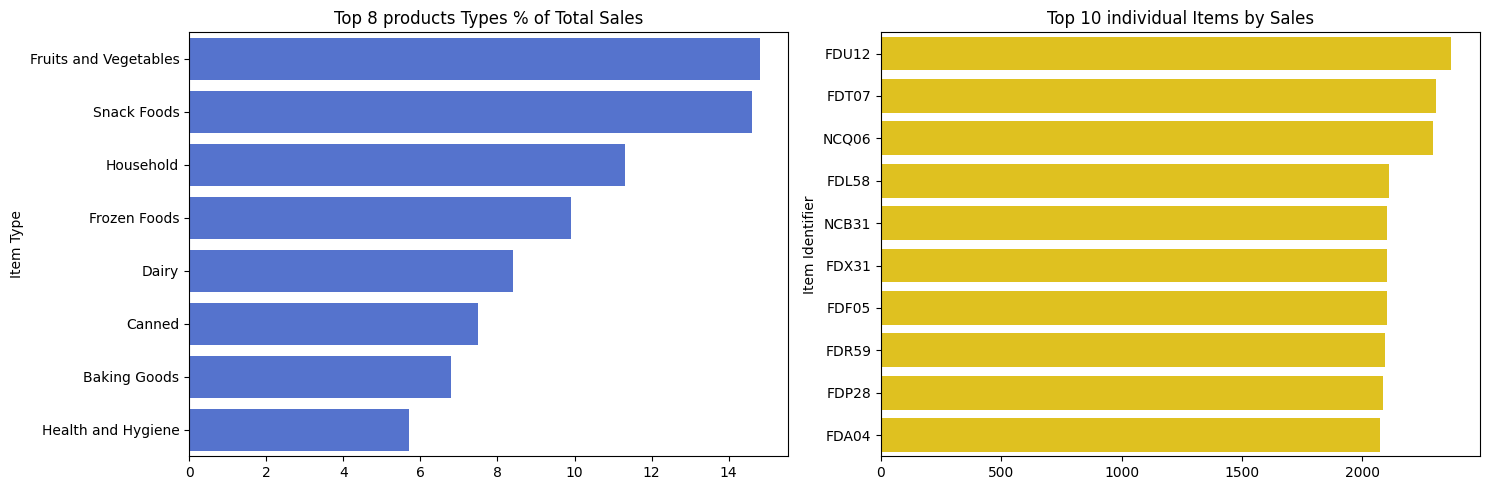

In [48]:
fig,ax=plt.subplots(1,2,figsize=(15,5))
sns.barplot(x=share.head(8).values,y=share.head(8).index,color="royalblue",ax=ax[0])
ax[0].set_title("Top 8 products Types % of Total Sales")
sns.barplot(x=top_items.values,y=top_items.index,color="gold",ax=ax[1])
ax[1].set_title("Top 10 individual Items by Sales")
plt.tight_layout()
plt.show()

Identify the Outlets and Locations that are performing better
-------------------------------------------------------------

In [49]:
outlet = df.groupby(["Outlet Identifier","Outlet Type","Outlet Location Type","Outlet Size"])["Sales"].agg(["sum","mean"]).reset_index()
outlet=outlet.sort_values("sum",ascending=False)
print(outlet.round(1).to_string(index=False))


Outlet Identifier       Outlet Type Outlet Location Type Outlet Size      sum  mean
           OUT035 Supermarket Type1               Tier 2       Small 133103.9 143.1
           OUT046 Supermarket Type1               Tier 1       Small 132113.4 142.1
           OUT013 Supermarket Type1               Tier 3        High 131809.0 141.4
           OUT018 Supermarket Type2               Tier 3      Medium 131477.8 141.7
           OUT027 Supermarket Type3               Tier 3      Medium 130714.7 139.8
           OUT049 Supermarket Type1               Tier 1      Medium 130476.9 140.3
           OUT019     Grocery Store               Tier 1       Small  73807.6 139.8
           OUT017 Supermarket Type1               Tier 2       Small  50121.9 136.2
           OUT045 Supermarket Type1               Tier 2       Small  47264.1 145.0
           OUT017 Supermarket Type1               Tier 2        High  45056.2 143.5
           OUT045 Supermarket Type1               Tier 2      Medium  44122.

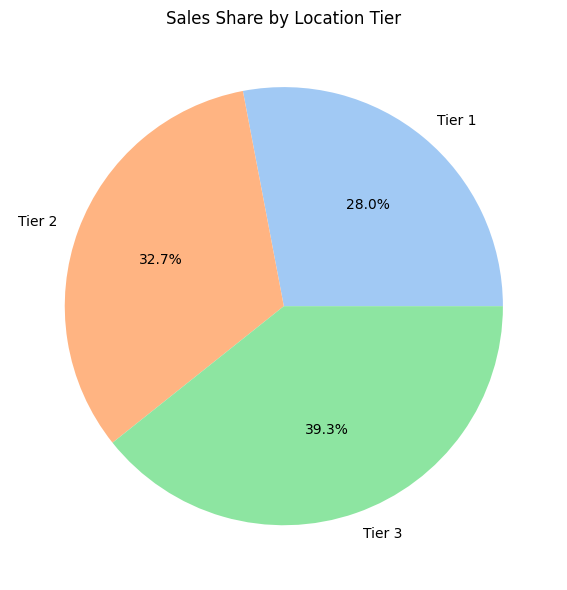

In [50]:
loc=df.groupby("Outlet Location Type")["Sales"].sum()
plt.figure(figsize=(6,6))
plt.pie(loc.values,labels=loc.index,autopct="%1.1f%%",colors=sns.color_palette("pastel"))
plt.title("Sales Share by Location Tier")
plt.tight_layout()
plt.show()

Identify products,outlets,and areas where performance can be improved
---------------------------------------------------------------------

In [51]:
w_types=df.groupby("Item Type")["Sales"].mean().sort_values().head(5)
w_outlets=df.groupby("Outlet Identifier")["Sales"].sum().sort_values().head(3)
area_sales=df.groupby("Outlet Location Type")["Sales"].mean().sort_values()
print("\nproduct types:\n",w_types.round(0))
print("\noutlets:\n",w_outlets.round(0))
print("\nAverage Sales by Area:\n",area_sales.round(0))


product types:
 Item Type
Baking Goods          126.0
Health and Hygiene    131.0
Soft Drinks           131.0
Others                133.0
Hard Drinks           137.0
Name: Sales, dtype: float64

outlets:
 Outlet Identifier
OUT019     73808.0
OUT010     78132.0
OUT017    129104.0
Name: Sales, dtype: float64

Average Sales by Area:
 Outlet Location Type
Tier 1    141.0
Tier 3    141.0
Tier 2    141.0
Name: Sales, dtype: float64


In [52]:
avg_by_type=df.groupby("Item Type")["Sales"].mean().sort_values()
print("\naverage sales per records:\n",avg_by_type.head(5).round(2))


average sales per records:
 Item Type
Baking Goods          126.38
Health and Hygiene    130.82
Soft Drinks           131.49
Others                132.85
Hard Drinks           137.08
Name: Sales, dtype: float64


In [53]:
pivot2=df.pivot_table(values="Sales",index="Outlet Size",columns="Outlet Location Type",aggfunc="mean")
print("\n",pivot2.round(1))


 Outlet Location Type  Tier 1  Tier 2  Tier 3
Outlet Size                                 
High                     NaN   143.9   141.1
Medium                 140.3   136.2   140.7
Small                  141.2   141.9   147.1


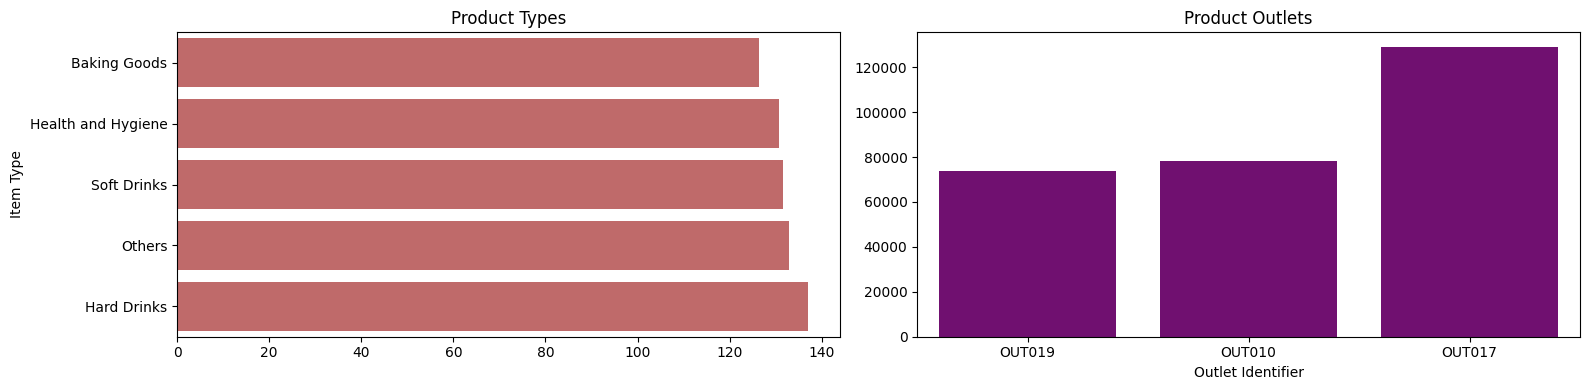

In [55]:
fig,ax=plt.subplots(1,2,figsize=(16,4))
sns.barplot(x=w_types.values,y=w_types.index,color="indianred",ax=ax[0])
ax[0].set_title("Product Types")
sns.barplot(x=w_outlets.index,y=w_outlets.values,color="Purple",ax=ax[1])
ax[1].set_title("Product Outlets")
plt.tight_layout()
plt.show()

Provide practical suggestion to improve sales and overall business performance
------------------------------------------------------------------------------

In [ ]:
print("""
KEY FINDINGS
1. Total sales = 1.20 million. Average sale per record = 141. Average rating = 3.97 out of 5.
2. Fruits & Vegetables and Snack Foods are the top 2 product types (about 15% of sales each).
   Household is 3rd (11%). Seafood, Breakfast and Starchy Foods sell the least.
3. Supermarket Type1 gives ~65% of total sales, but only because it has the most records and outlets.
   Sales PER record is almost the same (about 140) for every outlet type.
4. Visibility, weight, rating and outlet age have almost NO correlation with sales (all close to 0).
   So these factors alone do not explain sales - sales depend more on the number of items sold.
5. The 8 supermarkets each sell about 130,000 in total. The 2 Grocery Stores (OUT019, OUT010) sell only 74,000-78,000,
   because they have only about 540 records each versus about 930 for a supermarket. Sales per record is the same.

RECOMMENDATIONS
1. Stock more Fruits & Vegetables, Snack Foods, Household and Dairy - they are the biggest sales drivers.
2. Grow low-selling categories (Seafood, Breakfast, Starchy Foods) with offers and bundles, or reduce their stock.
3. Grocery Stores (OUT010, OUT019) sell about 40% less in total only because they stock fewer products.
   Widening their range to about 900 items is the easiest way to lift their sales.
4. OUT035 (Tier 2) is the top outlet and OUT017 the lowest supermarket (about 3% lower). Learn from OUT035's range and layout.
5. Do not rely on shelf visibility alone to raise sales - test it with a controlled experiment first.
6. Improve ratings: the average is 3.97 and Baking Goods and Health & Hygiene sell below average per record.
7. Fix the data at the source: standard fat-content labels, one size per outlet, no zero visibility, no missing weight.
""")